In [ ]:
import cv2
import os
from google.colab import drive
from google.colab.patches import cv2_imshow

In [ ]:
import matplotlib.pyplot as plt
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
config_file = '/content/drive/MyDrive/Colab Notebooks/ssd_mobilenet_v3_large_coco_2020_01_14.pbtxt'
frozen_model = '/content/drive/MyDrive/Colab Notebooks/frozen_inference_graph.pb'

In [ ]:
model = cv2.dnn_DetectionModel(frozen_model,config_file)

In [ ]:
classLabels = []
file_name = '/content/drive/MyDrive/Colab Notebooks/Labels.txt'
with open(file_name,'rt') as fpt:
  classLabels = fpt.read().rstrip('\n').split('\n')

In [ ]:
print(classLabels)

['person', 'bicycle', 'car', 'motorbike', 'aeroplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'sofa', 'pottedplant', 'bed', 'diningtable', 'toilet', 'tvmonitor', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


In [ ]:
print(len(classLabels))

80


In [ ]:
model.setInputSize(320,320)
model.setInputScale(1.0/127.5)
model.setInputMean((127.5,127.5,127.5))
model.setInputSwapRB(True)

< cv2.dnn.Model 0x7f9bee967730>

## **Reading an Image**


In [ ]:
img = cv2.imread('/content/drive/MyDrive/Colab Notebooks/bmw2.jpg')

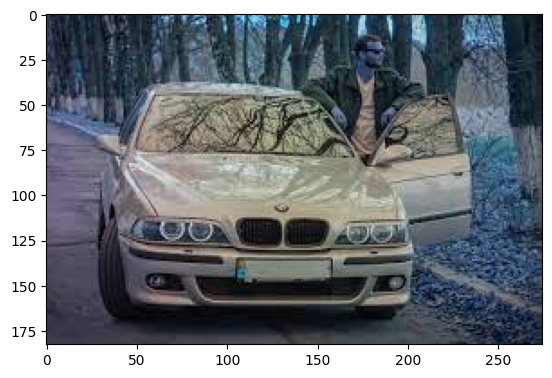

In [ ]:
plt.imshow(img) ##BGR

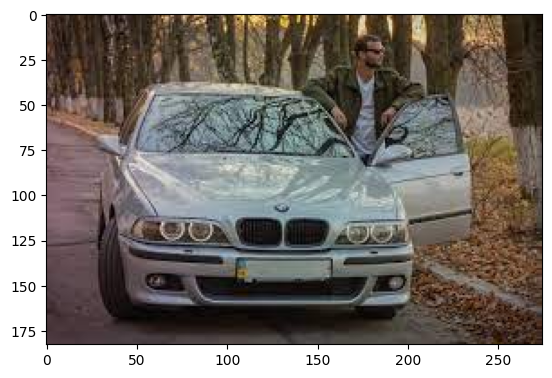

In [ ]:
plt.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))

In [ ]:
ClassIndex, confidence, bbox = model.detect(img,confThreshold=0.5)

In [ ]:
print(ClassIndex)

[3 1]


In [ ]:
font_scale = 3
font = cv2.FONT_HERSHEY_PLAIN

for ClassInd, conf, boxes in zip(ClassIndex.flatten(), confidence.flatten(), bbox):
    cv2.rectangle(img, boxes, (255, 0, 0), 2)
    cv2.putText(img, classLabels[ClassInd-1], (boxes[0]+5, boxes[1]+20), font, fontScale=font_scale, color=(0, 255, 0), thickness=1)

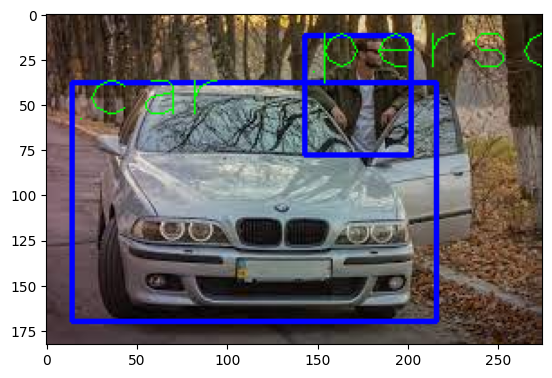

In [ ]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

**VIDEO DEMOSTRATION**

[1 1 3 1 1 1 1]


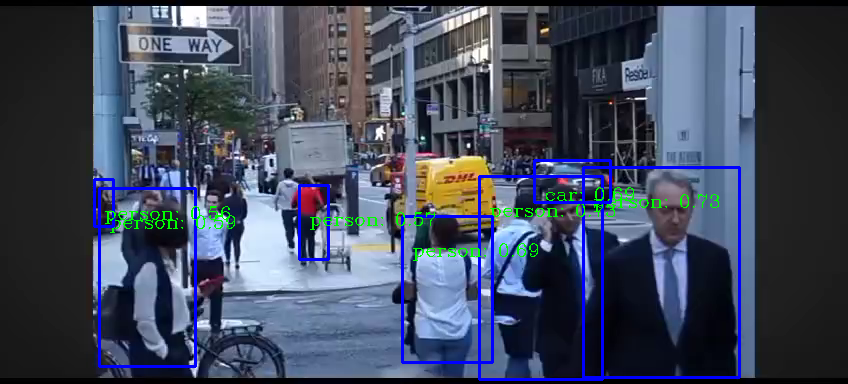

[1 1 3 1 1 1 1]


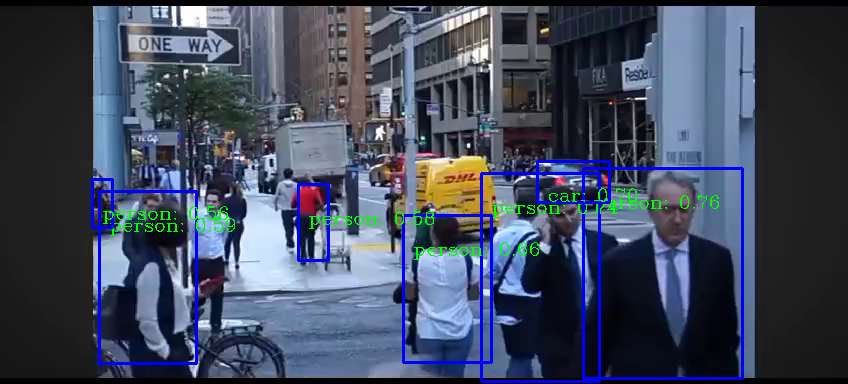

[1 1 3 1 1 1 1]


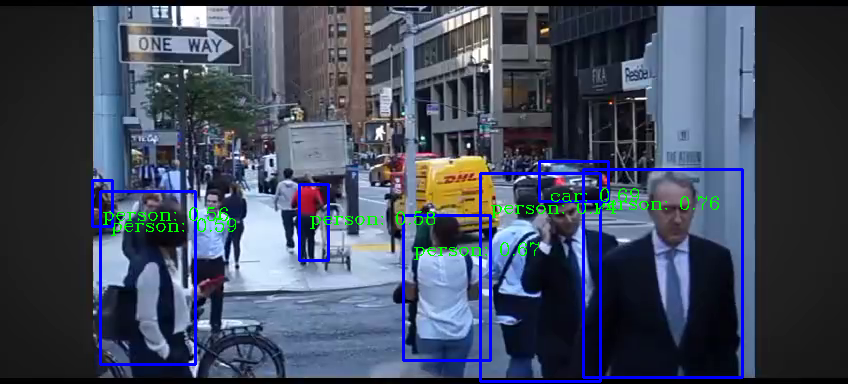

[1 1 3 1 1 1 1]


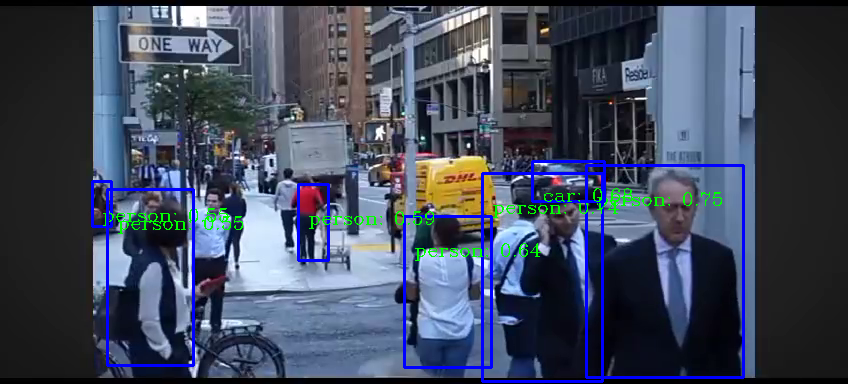

[1 1 3 1 1 2 1 1]


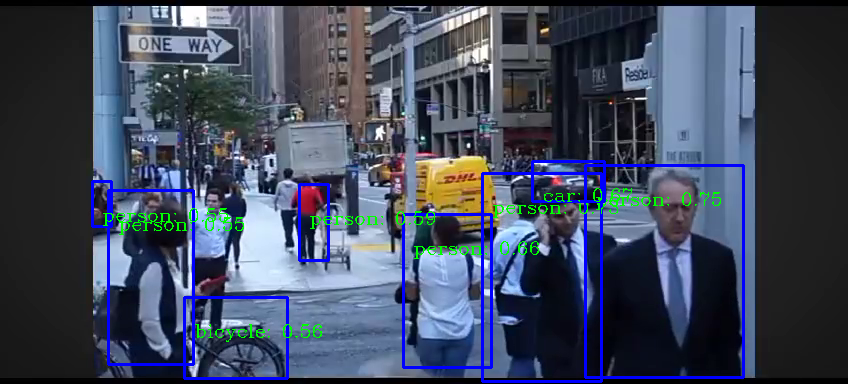

In [ ]:
cap = cv2.VideoCapture("/content/drive/MyDrive/Colab Notebooks/BG4.mp4")

# if you want to chnage it from video format to real time (web) format; just simply change path of the video "/content/drive/MyDrive/Colab Notebooks/BG4.mp4" to [0 or 1] depending on how many cameras are attacked on your system

if not cap.isOpened():
    cap = cv2.VideoCapture(0)
if not cap.isOpened():
    raise IOError("Cannot open video")

font_scale = 0.1  # Adjust the font scale to your preference
font = cv2.FONT_HERSHEY_COMPLEX

while True:
    ret, frame = cap.read()

    if not ret:
        print("Failed to capture frame. Exiting...")
        break

    ClassIndex, confidence, bbox = model.detect(frame, confThreshold=0.55)

    print(ClassIndex)
    if len(ClassIndex) != 0:
        for ClassInd, conf, boxes in zip(ClassIndex.flatten(), confidence.flatten(), bbox):
            if ClassInd <= 80:
                cv2.rectangle(frame, boxes, (255, 0, 0), 2)
                cv2.putText(frame, f"{classLabels[ClassInd-1]}: {conf:.2f}", (boxes[0]+10, boxes[1]+40), font, fontScale=font_scale, color=(0, 255, 0))

        cv2_imshow(frame)

    if cv2.waitKey(2) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()